## Summary of the Travel Insurance Prediction Project

### Steps covered
##### Data Exploration
##### Data Visualization
##### Feature Enginnering
##### Model training (All Supervised Learing Models)
##### Validation Tests

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter("ignore")

## DATA EXPLORATION

In [2]:
data = pd.read_csv("TravelInsurancePrediction.csv")


In [3]:
data.head(10)

,Unnamed: 0,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,0,31,Government Sector,Yes,400000,6,1,No,No,0
1,1,31,Private Sector/Self Employed,Yes,1250000,7,0,No,No,0
2,2,34,Private Sector/Self Employed,Yes,500000,4,1,No,No,1
3,3,28,Private Sector/Self Employed,Yes,700000,3,1,No,No,0
4,4,28,Private Sector/Self Employed,Yes,700000,8,1,Yes,No,0
5,5,25,Private Sector/Self Employed,No,1150000,4,0,No,No,0
6,6,31,Government Sector,Yes,1300000,4,0,No,No,0
7,7,31,Private Sector/Self Employed,Yes,1350000,3,0,Yes,Yes,1
8,8,28,Private Sector/Self Employed,Yes,1450000,6,1,Yes,Yes,1
9,9,33,Government Sector,Yes,800000,3,0,Yes,No,0


#### Check the data set it have any null value

In [4]:
data.isna().sum()

Unnamed: 0             0
Age                    0
Employment Type        0
GraduateOrNot          0
AnnualIncome           0
FamilyMembers          0
ChronicDiseases        0
FrequentFlyer          0
EverTravelledAbroad    0
TravelInsurance        0
dtype: int64

In [5]:
## dropping few columns form the dataset
data.drop(["Unnamed: 0","GraduateOrNot"], axis=1, inplace = True)

In [6]:
data.columns

Index(['Age', 'Employment Type', 'AnnualIncome', 'FamilyMembers',
       'ChronicDiseases', 'FrequentFlyer', 'EverTravelledAbroad',
       'TravelInsurance'],
      dtype='str')

In [7]:
data.describe()

,Age,AnnualIncome,FamilyMembers,ChronicDiseases,TravelInsurance
count,1987.000000,1.987000e+03,1987.000000,1987.000000,1987.000000
mean,29.650226,9.327630e+05,4.752894,0.277806,0.357323
std,2.913308,3.768557e+05,1.609650,0.448030,0.479332
min,25.000000,3.000000e+05,2.000000,0.000000,0.000000
25%,28.000000,6.000000e+05,4.000000,0.000000,0.000000
50%,29.000000,9.000000e+05,5.000000,0.000000,0.000000
75%,32.000000,1.250000e+06,6.000000,1.000000,1.000000
max,35.000000,1.800000e+06,9.000000,1.000000,1.000000


## DATA VISUALIZATION

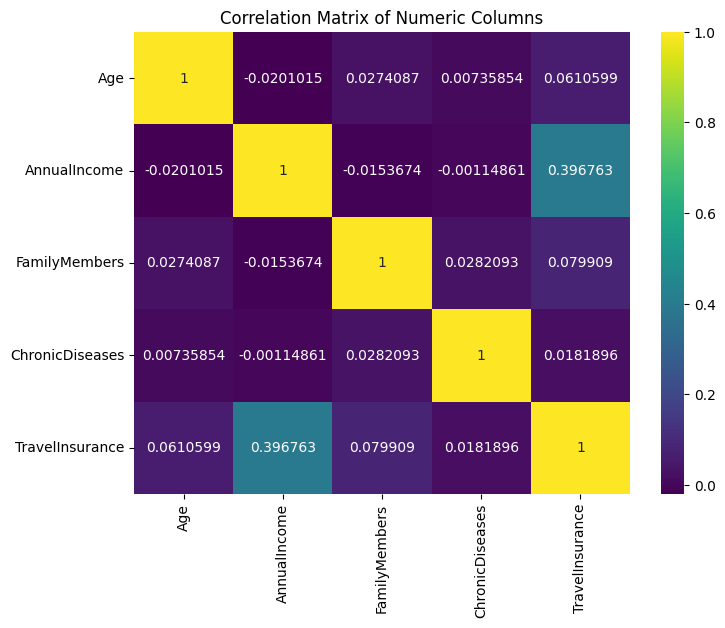

In [8]:
### heatmap for correlation

## select only numeric columns for correlation
numeric_data = data.select_dtypes(include = 'number')

#plot the correlations heatmap
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(numeric_data.corr(),annot=True,fmt='1g',cmap="viridis", cbar=True)
plt.title("Correlation Matrix of Numeric Columns")
plt.show()


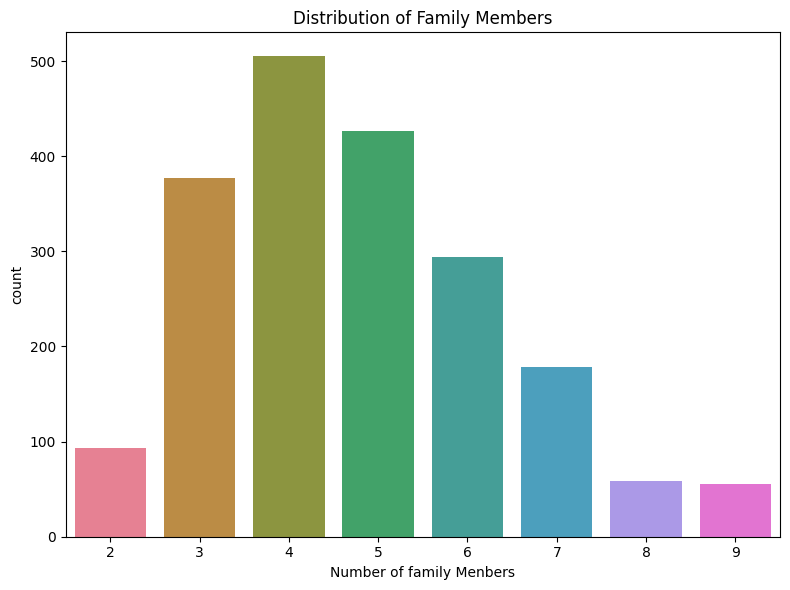

In [9]:
## clount plot
## create a colour palette with as many colours as there are unique family member values
unique_families = data["FamilyMembers"].nunique()
palette = sns.color_palette("husl",unique_families)


#plot
fig,ax = plt.subplots(figsize=(8,6))
sns.countplot(x ="FamilyMembers",data=data,palette=palette,ax=ax)


#beasutify
ax.set_title("Distribution of Family Members")
ax.set_xlabel("Number of family Menbers")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()






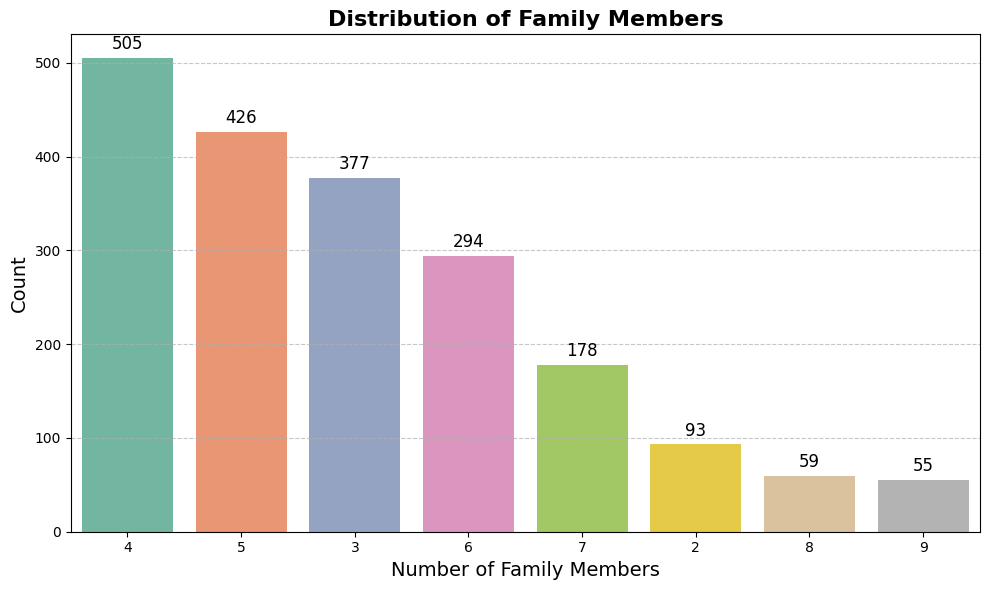

In [10]:
## Improved Count plot
## Create a colour palette with as many colours as there are unique family member values
unique_families = data["FamilyMembers"].nunique()
palette = sns.color_palette("Set2", unique_families)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(x="FamilyMembers", data=data, palette=palette, ax=ax, order=data["FamilyMembers"].value_counts().index)

# Beautify
ax.set_title("Distribution of Family Members", fontsize=16, fontweight='bold')
ax.set_xlabel("Number of Family Members", fontsize=14)
ax.set_ylabel("Count", fontsize=14)
ax.legend
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Add count annotations on bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10), textcoords='offset points', fontsize=12)

plt.tight_layout()
plt.show()

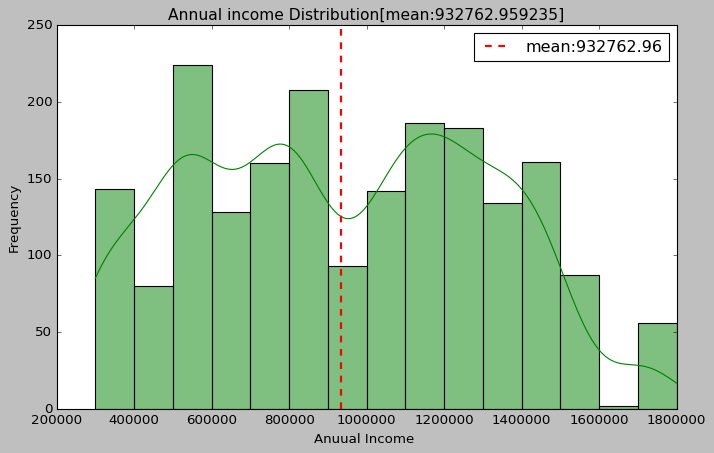

In [11]:
## create annual d
plt.style.use("classic")

## create the plot
fig, ax = plt.subplots(figsize=(10,6))
sns.histplot(data["AnnualIncome"],kde = True,color = "green",ax = ax)

##Beautify

mean_income = data["AnnualIncome"].mean()
ax.axvline(mean_income, color = 'red',linestyle='--',linewidth=2,label=f"mean:{mean_income:.2f}")
ax.set_title(f"Annual income Distribution[mean:{mean_income:2f}]",fontsize =14)
ax.set_xlabel("Anuual Income ",fontsize =12)
ax.set_ylabel("Frequency",fontsize=12)
ax.legend()
plt.tight_layout
plt.show()

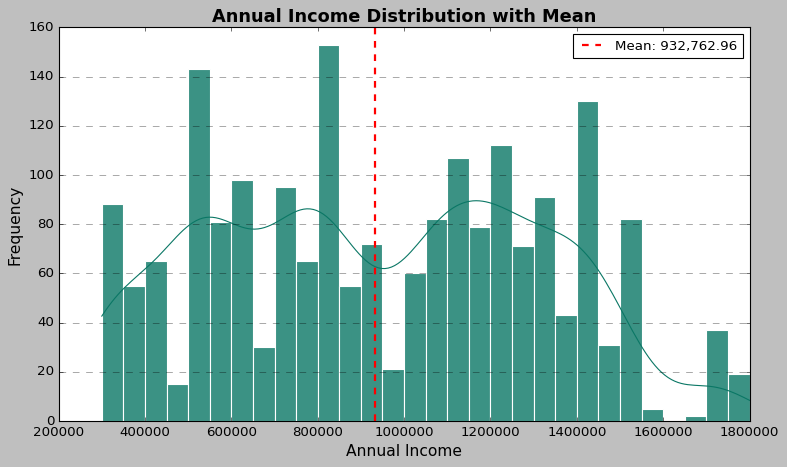

In [12]:
## Histogram of Annual Income with Mean Line
plt.figure(figsize=(10, 6))

mean_income = data['AnnualIncome'].mean()

sns.histplot(data['AnnualIncome'], bins=30, kde=True, color="#0a77655c", edgecolor='white', alpha=0.8)
plt.axvline(mean_income, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_income:,.2f}')

plt.title('Annual Income Distribution with Mean', fontsize=16, fontweight='bold')
plt.xlabel('Annual Income', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.legend(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

#### Distribution of chronic diseases

In [13]:
data.columns

Index(['Age', 'Employment Type', 'AnnualIncome', 'FamilyMembers',
       'ChronicDiseases', 'FrequentFlyer', 'EverTravelledAbroad',
       'TravelInsurance'],
      dtype='str')

In [14]:
#get value counts
disease_counts = data["ChronicDiseases"].value_counts()

print(disease_counts)


ChronicDiseases
0    1435
1     552
Name: count, dtype: int64


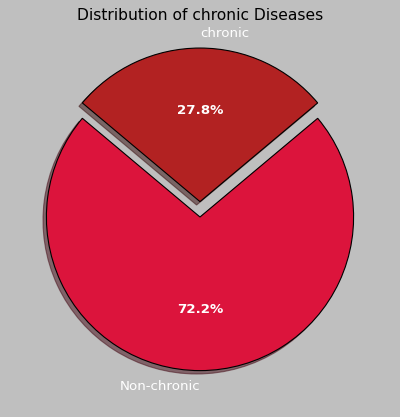

In [15]:
##create the plot
labels = ["Non-chronic","chronic"]


fig, ax = plt.subplots(figsize=(8,6))
wedges, texts, autotexts = ax.pie(
    x = disease_counts,
    labels = labels,
    colors = ["crimson","firebrick"],
    shadow = True,explode=(0,0.1),
    autopct="%1.1f%%",
    startangle=140,
    textprops=dict(color="white",fontsize=12),
)

ax.set_title("Distribution of chronic Diseases", fontsize=14)
plt.setp(autotexts,weight='bold')
plt.tight_layout
plt.show()

## Plot Improved  By Agents 

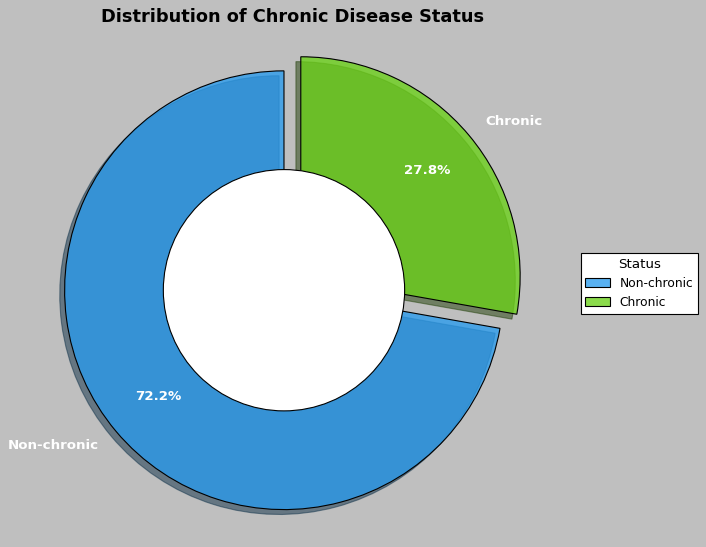

In [16]:
# Improved pie chart (new cell)
labels = ["Non-chronic", "Chronic"]
colors = ["#289beec5", "#6BD118C7"]

fig, ax = plt.subplots(figsize=(9, 7))
wedges, texts, autotexts = ax.pie(
    x=disease_counts,
    labels=labels,
    colors=colors,
    shadow=True,
    explode=(0, 0.1),
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.75,
    textprops=dict(color="white", fontsize=12, weight='bold'),
)

# Draw circle in center for donut style
centre_circle = plt.Circle((0, 0), 0.55, fc='white')
fig.gca().add_artist(centre_circle)

# Add legend outside plot
ax.legend(wedges, labels, title="Status", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1), fontsize=11)
ax.set_title("Distribution of Chronic Disease Status", fontsize=16, fontweight='bold')

# Set aspect ratio to equal for a perfect circle
ax.axis('equal')
plt.tight_layout()
plt.show()

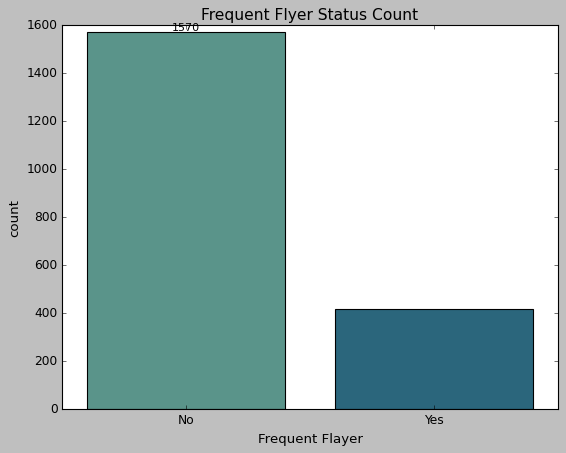

In [17]:
plt.style.use("classic")

#create the plot
fig, ax=plt.subplots(figsize=(8,6))
sns.countplot(x="FrequentFlyer", data=data,palette="crest",ax=ax)

#add butti
ax.set_title("Frequent Flyer Status Count",fontsize=14)
ax.set_xlabel("Frequent Flayer",fontsize=12)
ax.bar_label(ax.containers[0], label_type="edge",fontsize=10)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.tight_layout
plt.show()

#### Travel Insurance Distribution

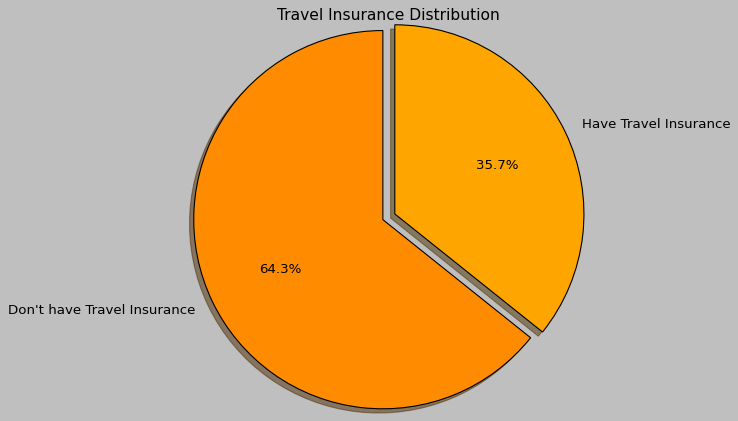

In [18]:
## pie chart values and lables
values= data["TravelInsurance"].value_counts()
labels=["Don't have Travel Insurance","Have Travel Insurance"]


## create pie chart
fig, ax=plt.subplots(figsize=(8,6))
ax.pie(
    x=values,
    labels=labels,
    colors=["darkorange","orange"],
    autopct="%1.1f%%",
    explode=(0,0.07),
    shadow=True,
    startangle=90,
    wedgeprops={"edgecolor":"black"}
)
ax.set_title("Travel Insurance Distribution",fontsize=14)
ax.axis("equal")

plt.tight_layout
plt.show()

## Feature Engineering

In [19]:
data.head()

,Age,Employment Type,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,31,Government Sector,400000,6,1,No,No,0
1,31,Private Sector/Self Employed,1250000,7,0,No,No,0
2,34,Private Sector/Self Employed,500000,4,1,No,No,1
3,28,Private Sector/Self Employed,700000,3,1,No,No,0
4,28,Private Sector/Self Employed,700000,8,1,Yes,No,0


In [20]:
data["FrequentFlyer"] = data["FrequentFlyer"].map({'Yes':1,'No':0})
data["EverTravelledAbroad"] = data["EverTravelledAbroad"].map({'Yes':1,'No':0})

##Goverment sector:1, private sector/self Emplyed:0
data["Employment Type"] = data["Employment Type"].map({"Government Sector":1,"Private Sector/Self Employed":0})

In [21]:
data.head(10)

,Age,Employment Type,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,31,1,400000,6,1,0,0,0
1,31,0,1250000,7,0,0,0,0
2,34,0,500000,4,1,0,0,1
3,28,0,700000,3,1,0,0,0
4,28,0,700000,8,1,1,0,0
5,25,0,1150000,4,0,0,0,0
6,31,1,1300000,4,0,0,0,0
7,31,0,1350000,3,0,1,1,1
8,28,0,1450000,6,1,1,1,1
9,33,1,800000,3,0,1,0,0


In [22]:
X = data.drop("TravelInsurance",axis=1)
X.head()

,Age,Employment Type,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad
0,31,1,400000,6,1,0,0
1,31,0,1250000,7,0,0,0
2,34,0,500000,4,1,0,0
3,28,0,700000,3,1,0,0
4,28,0,700000,8,1,1,0


In [23]:
y = data["TravelInsurance"]
y.head()

0    0
1    0
2    1
3    0
4    0
Name: TravelInsurance, dtype: int64

In [24]:
## splitiing the data into x train, x test and y train, y test
from sklearn.model_selection import train_test_split


In [25]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state = 42)

In [26]:
len(X_train),len(X_test)

(1589, 398)

In [27]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()

In [28]:
rf.fit(X_train,y_train)
rf

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [29]:
data.head()

,Age,Employment Type,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,31,1,400000,6,1,0,0,0
1,31,0,1250000,7,0,0,0,0
2,34,0,500000,4,1,0,0,1
3,28,0,700000,3,1,0,0,0
4,28,0,700000,8,1,1,0,0


In [30]:
RandomForestClassifier = rf.score(X_train,y_train)
print("RF_score",RandomForestClassifier)

print("Accuracy obtained by RandomForestClassifier MODELS :",RandomForestClassifier*100)

RF_score 0.920075519194462
Accuracy obtained by RandomForestClassifier MODELS : 92.0075519194462


### VALIDATION TESTS

In [31]:
from sklearn.model_selection import GridSearchCV

In [32]:
param_grid = {
    'bootstrap':[True],
    'max_depth':[80,90,100,110,120],
    'max_features':[2,3],
    'min_samples_leaf':[3,4,5],
    'criterion':['gini','entropy'],
    'n_estimators':[100,200,300,1000]
}

grid_search_rf = GridSearchCV(estimator = rf,
                              param_grid = param_grid,
                              cv = 3,n_jobs = -1,verbose = 2)

In [33]:
grid_search_rf.fit(X_train, y_train)

Fitting 3 folds for each of 240 candidates, totalling 720 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'bootstrap': [True], 'criterion': ['gini', 'entropy'], 'max_depth': [80, 90, ...], 'max_features': [2, 3], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selectio

In [34]:
grid_search_rf.best_params_

{'bootstrap': True,
 'criterion': 'gini',
 'max_depth': 110,
 'max_features': 2,
 'min_samples_leaf': 4,
 'n_estimators': 300}

In [35]:
grid_search_rf.best_score_

np.float64(0.83261047900988)

In [36]:
grid_search_rf_predict = grid_search_rf.predict(X_test)
grid_search_rf_predict

array([0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,

In [37]:
from sklearn.model_selection import cross_val_score

baseline_score = cross_val_score(rf, X, y, cv=5).mean()
improvement = 100 * (grid_search_rf.best_score_ - baseline_score) / baseline_score

In [38]:
from sklearn.metrics import classification_report

In [39]:
print(classification_report(y_test, grid_search_rf_predict))

              precision    recall  f1-score   support

           0       0.81      1.00      0.89       257
           1       0.99      0.57      0.72       141

    accuracy                           0.84       398
   macro avg       0.90      0.78      0.81       398
weighted avg       0.87      0.84      0.83       398



In [41]:
grid_search_rf_predict = grid_search_rf.predict(X_test)

In [42]:
from sklearn.metrics import classification_report

print(classification_report(y_test, grid_search_rf_predict))

              precision    recall  f1-score   support

           0       0.81      1.00      0.89       257
           1       0.99      0.57      0.72       141

    accuracy                           0.84       398
   macro avg       0.90      0.78      0.81       398
weighted avg       0.87      0.84      0.83       398



In [43]:
X = data.drop("TravelInsurance", axis=1)

In [44]:
print(X.columns.tolist())

['Age', 'Employment Type', 'AnnualIncome', 'FamilyMembers', 'ChronicDiseases', 'FrequentFlyer', 'EverTravelledAbroad']


In [45]:
new_customer = pd.DataFrame([{
    "Age": 30,
    "Employment Type": 0,
    "GraduateOrNot": 1,
    "AnnualIncome": 800000,
    "FamilyMembers": 3,
    "ChronicDiseases": 0,
    "FrequentFlyer": 1,
    "EverTravelledAbroad": 1
}])

In [46]:
new_customer = pd.DataFrame([{
    "Age": 30,
    "Employment Type": 0,
    "AnnualIncome": 800000,
    "FamilyMembers": 3,
    "ChronicDiseases": 0,
    "FrequentFlyer": 1,
    "EverTravelledAbroad": 1
}])

In [47]:
new_customer = new_customer[X.columns]

prediction = grid_search_rf.predict(new_customer)

print("Prediction:", prediction[0])

Prediction: 0


In [48]:
probabilities = grid_search_rf.predict_proba(new_customer)

print(probabilities)

[[0.67147109 0.32852891]]


In [49]:
purchase_probability = grid_search_rf.predict_proba(
    new_customer
)[0, 1]

print(f"Purchase probability: {purchase_probability:.2%}")

Purchase probability: 32.85%


In [51]:
pip install joblib

Note: you may need to restart the kernel to use updated packages.


In [50]:
import joblib

joblib.dump(grid_search_rf, "travel_insurance_model.pkl")

['travel_insurance_model.pkl']

In [52]:
import joblib

model = joblib.load("travel_insurance_model.pkl")

In [53]:
prediction = model.predict(new_customer)

print(prediction[0])

0
